### 1. Utilizar modelos treinados para gerar predições 

#### 1.1.  Reunir modelos treinados, fazer as predições e salvar
Importante: salvar tempo de inferência 

In [7]:
# save as: run_inference_all.py
from __future__ import annotations

import os
import re
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Optional, Tuple, Dict, List

import numpy as np
import pandas as pd

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras

# Sklearn scaler (mesmo padrão dos seus treinos)
from sklearn.preprocessing import MinMaxScaler

# ====== Config GPU (opcional) ======
def setup_gpu():
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        try:
            tf.config.set_visible_devices(gpus[0], "GPU")
            tf.config.experimental.set_memory_growth(gpus[0], True)
            print(f"[GPU] Usando: {gpus[0].name}")
        except RuntimeError as e:
            print("[GPU] Aviso:", e)
    else:
        print("[GPU] Nenhuma GPU detectada (ok, vai CPU).")


# ====== Helpers dados ======
def bits_para_megabits(series: pd.Series) -> pd.Series:
    # seu treino: df[col] = df[col] / 1_000_000 ; -1 -> NaN
    s = series.astype("float64") / 1_000_000.0
    s = s.replace(-1, np.nan)
    return s


def linear_interpolation(series: pd.Series) -> pd.Series:
    s = series.copy()
    s_interp = s.interpolate(method="linear", limit_direction="both")
    return s.fillna(s_interp)


def resample_6h(df: pd.DataFrame, how: str = "mean") -> pd.DataFrame:
    """
    Tratamento 6 em 6 horas usando a coluna 'Data' como timestamp real.
    how: mean | sum | median | max | min
    """
    g = df.copy()

    # Data é o timestamp real; Timestamp é aquele "1970..." (provavelmente índice artificial)
    g["Data"] = pd.to_datetime(g["Data"], errors="coerce")
    g = g.dropna(subset=["Data"]).sort_values("Data")

    # Vazao em Mbits/s como nos treinos
    g["Vazao"] = bits_para_megabits(g["Vazao"])

    # index para resample
    g = g.set_index("Data")

    if how == "mean":
        agg = g[["Vazao"]].resample("6H").mean()
    elif how == "sum":
        agg = g[["Vazao"]].resample("6H").sum()
    elif how == "median":
        agg = g[["Vazao"]].resample("6H").median()
    elif how == "max":
        agg = g[["Vazao"]].resample("6H").max()
    elif how == "min":
        agg = g[["Vazao"]].resample("6H").min()
    else:
        raise ValueError(f"how inválido: {how}")

    agg = agg.reset_index()  # volta com coluna Data
    return agg


def split_train_test(values: np.ndarray, train_ratio: float = 0.8) -> Tuple[np.ndarray, np.ndarray]:
    n = len(values)
    n_train = int(n * train_ratio)
    train = values[:n_train]
    test = values[n_train:]
    return train, test


# ====== Inferência GRU/LSTM (lookback=1) ======
def infer_gru_lstm_one_step(
    model: keras.Model,
    series_mbps: np.ndarray,
    train_ratio: float = 0.8,
) -> Tuple[np.ndarray, np.ndarray, float]:
    """
    Replica seu pipeline:
      - interpolação no treino
      - scaler fit no treino
      - X_test = test_scaled[:-1] (shape (N,1,1))
      - pred = model.predict(X_test)
    Retorna:
      y_true (orig), y_pred (orig), inference_time_sec
    """
    s = series_mbps.astype("float64").reshape(-1, 1)

    train, test = split_train_test(s, train_ratio=train_ratio)

    # interp apenas no treino (como você fez)
    train_s = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)

    scaler = MinMaxScaler().fit(train_s)
    test_scaled = scaler.transform(test)

    # next-step
    X_test = test_scaled[:-1]
    y_true_scaled = test_scaled[1:]

    X_test_reshaped = X_test.reshape((X_test.shape[0], 1, 1))

    t0 = time.perf_counter()
    y_pred_scaled = model.predict(X_test_reshaped, verbose=0)
    t1 = time.perf_counter()

    y_pred = scaler.inverse_transform(y_pred_scaled).flatten()
    y_true = scaler.inverse_transform(y_true_scaled).flatten()
    return y_true, y_pred, (t1 - t0)


# ====== Inferência recursiva LSTM (lookback=3, walk-forward híbrido) ======
def walk_forward_validation_hybrid_loaded(
    model: keras.Model,
    scaler: MinMaxScaler,
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    mask_test: np.ndarray,
    look_back: int,
    window_size: int,
) -> List[float]:
    """
    Igual ao seu walk_forward_validation_hybrid:
    - estado inicial = últimos look_back pontos do treino
    - para cada janela, faz previsão ponto-a-ponto e alimenta:
        se mask diz que tem ponto real: usa o real; senão usa a previsão (scaled)
    Retorna predições em escala original (Mbits/s)
    """
    state = train_scaled[-look_back:].reshape(1, look_back, 1)
    predictions = []

    for i in range(0, len(test_scaled), window_size):
        end_idx = min(i + window_size, len(test_scaled))
        window_data = test_scaled[i:end_idx]
        window_mask = mask_test[i:end_idx]

        current_state = state
        for j in range(len(window_data)):
            pred_scaled = model.predict(current_state, verbose=0)
            pred_orig = scaler.inverse_transform(pred_scaled)[0, 0]
            predictions.append(float(pred_orig))

            if window_mask[j]:
                new_point = window_data[j].item()
            else:
                new_point = pred_scaled[0, 0]

            current_state = np.roll(current_state, -1, axis=1)
            current_state[0, -1, 0] = new_point

        state = current_state

    return predictions


def infer_recursive_lstm(
    model: keras.Model,
    series_mbps: np.ndarray,
    train_ratio: float = 0.8,
    look_back: int = 3,
    window_size: int = 28,
) -> Tuple[np.ndarray, np.ndarray, float]:
    """
    Replica seu pipeline da recursiva (sem retreinar):
      - mask_total = ~(isna | ==-1) (aqui -1 já virou NaN na conversão)
      - interp no treino
      - scaler fit treino
      - train_scaled/test_scaled
      - walk forward híbrido
      - alinha y_true = test_scaled[look_back: look_back+min_len]
    Retorna:
      y_true(orig), y_pred(orig), inference_time_sec
    """
    s = series_mbps.astype("float64").reshape(-1, 1)

    # mask: pontos válidos (antes da interp)
    mask_total = ~pd.isna(s.flatten())

    train, test = split_train_test(s, train_ratio=train_ratio)
    train_mask = mask_total[: len(train)]
    test_mask = mask_total[len(train):]

    train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)

    scaler = MinMaxScaler().fit(train_interp)
    train_scaled = scaler.transform(train_interp)
    test_scaled = scaler.transform(test)

    # mask_test alinhada ao test_scaled
    mask_test = test_mask.astype(bool)

    t0 = time.perf_counter()
    preds = walk_forward_validation_hybrid_loaded(
        model=model,
        scaler=scaler,
        train_scaled=train_scaled,
        test_scaled=test_scaled,
        mask_test=mask_test,
        look_back=look_back,
        window_size=window_size,
    )
    t1 = time.perf_counter()

    # Alinhamento como no seu código
    min_len = min(len(preds), len(test_scaled) - look_back)
    y_true_scaled = test_scaled[look_back : look_back + min_len]
    y_true = scaler.inverse_transform(y_true_scaled).flatten()
    y_pred = np.array(preds[:min_len], dtype="float64").flatten()

    return y_true, y_pred, (t1 - t0)


# ====== Matching de nomes ======
@dataclass
class ModelPaths:
    proposal_dir: Path     # results/.../models  (arquivos .keras)
    gru_lstm_dir: Path     # results2/.../models (arquivos .h5)


def dataset_key_from_csv(csv_path: Path) -> str:
    # ex: ac-am_bbr_interval_0.csv -> ac-am_bbr_interval_0
    return csv_path.stem


def find_model_files(model_paths: ModelPaths, key: str) -> Dict[str, Optional[Path]]:
    """
    key já inclui protocolo (ex: ac-am_bbr_interval_0).
    Retorna caminhos para:
      - PROPOSTA (.keras): key + ".keras"
      - GRU (.h5): key + "_GRU.h5"
      - LSTM (.h5): key + "_LSTM.h5"
    """
    out = {
        "PROPOSTA": None,
        "GRU": None,
        "LSTM": None,
    }

    p_proposta = model_paths.proposal_dir / f"{key}.keras"
    if p_proposta.exists():
        out["PROPOSTA"] = p_proposta

    p_gru = model_paths.gru_lstm_dir / f"{key}_GRU.h5"
    if p_gru.exists():
        out["GRU"] = p_gru

    p_lstm = model_paths.gru_lstm_dir / f"{key}_LSTM.h5"
    if p_lstm.exists():
        out["LSTM"] = p_lstm

    return out


# ====== Main runner ======
def run(
    base_dir: Path,
    out_csv: Path,
    resample_how: str = "mean",
    do_sarima: bool = False,  # por padrão: não roda SARIMA (não tem modelo salvo)
):
    setup_gpu()

    treated_dir = base_dir / "treated" / "treated"
    results_dir = base_dir / "results"
    results2_dir = base_dir / "results2"

    rows = []

    for protocol in ["bbr", "cubic"]:
        data_dir = treated_dir / protocol
        if not data_dir.exists():
            print(f"[WARN] Pasta não encontrada: {data_dir}")
            continue

        model_paths = ModelPaths(
            proposal_dir=(results_dir / protocol / "models"),
            gru_lstm_dir=(results2_dir / protocol / "models"),
        )

        csv_files = sorted(data_dir.glob("*.csv"))
        print(f"[INFO] {protocol}: {len(csv_files)} arquivos CSV")

        for csv_path in csv_files:
            key = dataset_key_from_csv(csv_path)

            # Carrega e trata 6h
            try:
                df = pd.read_csv(csv_path)
            except Exception as e:
                print(f"[ERRO] Lendo {csv_path.name}: {e}")
                continue

            # exige colunas
            if not {"Data", "Vazao"}.issubset(df.columns):
                print(f"[SKIP] {csv_path.name}: colunas esperadas faltando (Data, Vazao).")
                continue

            df6 = resample_6h(df, how=resample_how)

            # Série final (Mbits/s) com NaN possíveis
            series = df6["Vazao"].astype("float64").values

            # Se tudo NaN ou muito curto, pula
            valid_count = np.sum(~pd.isna(series))
            if valid_count < 10:
                print(f"[SKIP] {csv_path.name}: poucos pontos válidos após 6h (valid={valid_count}).")
                continue

            model_files = find_model_files(model_paths, key)

            # ---- PROPOSTA (.keras) ----
            if model_files["PROPOSTA"] is not None:
                mp = model_files["PROPOSTA"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred, infer_t = infer_recursive_lstm(
                        model=model,
                        series_mbps=series,
                        look_back=3,
                        window_size=28,
                    )
                    rows.append({
                        "protocol": protocol,
                        "dataset": key,
                        "model": "PROPOSTA",
                        "model_path": str(mp),
                        "n_points_6h": int(len(series)),
                        "n_valid_6h": int(valid_count),
                        "inference_time_sec": float(infer_t),
                        "y_len": int(len(y_true)),
                    })
                    print(f"[OK] {key} PROPOSTA infer={infer_t:.4f}s len={len(y_true)}")
                except Exception as e:
                    print(f"[ERRO] {key} PROPOSTA: {e}")

            # ---- GRU (.h5) ----
            if model_files["GRU"] is not None:
                mp = model_files["GRU"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred, infer_t = infer_gru_lstm_one_step(
                        model=model,
                        series_mbps=series,
                    )
                    rows.append({
                        "protocol": protocol,
                        "dataset": key,
                        "model": "GRU",
                        "model_path": str(mp),
                        "n_points_6h": int(len(series)),
                        "n_valid_6h": int(valid_count),
                        "inference_time_sec": float(infer_t),
                        "y_len": int(len(y_true)),
                    })
                    print(f"[OK] {key} GRU infer={infer_t:.4f}s len={len(y_true)}")
                except Exception as e:
                    print(f"[ERRO] {key} GRU: {e}")

            # ---- LSTM (.h5) ----
            if model_files["LSTM"] is not None:
                mp = model_files["LSTM"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred, infer_t = infer_gru_lstm_one_step(
                        model=model,
                        series_mbps=series,
                    )
                    rows.append({
                        "protocol": protocol,
                        "dataset": key,
                        "model": "LSTM",
                        "model_path": str(mp),
                        "n_points_6h": int(len(series)),
                        "n_valid_6h": int(valid_count),
                        "inference_time_sec": float(infer_t),
                        "y_len": int(len(y_true)),
                    })
                    print(f"[OK] {key} LSTM infer={infer_t:.4f}s len={len(y_true)}")
                except Exception as e:
                    print(f"[ERRO] {key} LSTM: {e}")

            # ---- SARIMA (opcional) ----
            if do_sarima:
                # Se você quiser, dá pra medir SARIMA “do zero” aqui.
                # Mas por padrão está desligado.
                pass

    out_csv.parent.mkdir(parents=True, exist_ok=True)
    out_df = pd.DataFrame(rows).sort_values(["protocol", "dataset", "model"])
    out_df.to_csv(out_csv, index=False, encoding="utf-8")
    print(f"\n[DONE] Salvou: {out_csv}  (rows={len(out_df)})")

In [8]:
from pathlib import Path


In [9]:
# ====== Parâmetros (equivalente ao argparse) ======

BASE_DIR = Path("./")

OUT_CSV = Path("./inference_times.csv")

# Agregação do resample 6H
# opções: "mean", "sum", "median", "max", "min"
RESAMPLE_HOW = "mean"

# SARIMA (por padrão desligado, igual ao script)
DO_SARIMA = False


In [10]:
print("Base dir existe:", BASE_DIR.exists())
print("Treated dir existe:", (BASE_DIR / "treated" / "treated").exists())
print("Results dir existe:", (BASE_DIR / "results").exists())
print("Results2 dir existe:", (BASE_DIR / "results2").exists())


Base dir existe: True
Treated dir existe: True
Results dir existe: True
Results2 dir existe: True


In [11]:
run(
    base_dir=BASE_DIR,
    out_csv=OUT_CSV,
    resample_how=RESAMPLE_HOW,
    do_sarima=DO_SARIMA,
)


[GPU] Nenhuma GPU detectada (ok, vai CPU).
[INFO] bbr: 399 arquivos CSV


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()


[OK] ac-ap_bbr_interval_0 PROPOSTA infer=28.2684s len=440


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()


[OK] ac-go_bbr_interval_0 PROPOSTA infer=29.2379s len=440
[OK] ac-go_bbr_interval_0 GRU infer=0.3518s len=442
[OK] ac-go_bbr_interval_0 LSTM infer=0.2736s len=442


...

C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()


[OK] to-pr_cubic_interval_0 PROPOSTA infer=21.2821s len=440


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()


[OK] to-rr_cubic_interval_0 PROPOSTA infer=20.6997s len=424

[DONE] Salvou: inference_times.csv  (rows=457)


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3230299753.py:67: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = g[["Vazao"]].resample("6H").mean()


In [12]:
import pandas as pd

df_results = pd.read_csv(OUT_CSV)
df_results.head()


,protocol,dataset,model,model_path,n_points_6h,n_valid_6h,inference_time_sec,y_len
0,bbr,ac-ap_bbr_interval_0,PROPOSTA,results\bbr\models\ac-ap_bbr_interval_0.keras,2213,1475,28.268407,440
1,bbr,ac-go_bbr_interval_0,GRU,results2\bbr\models\ac-go_bbr_interval_0_GRU.h5,2211,1395,0.351843,442
2,bbr,ac-go_bbr_interval_0,LSTM,results2\bbr\models\ac-go_bbr_interval_0_LSTM.h5,2211,1395,0.273598,442
3,bbr,ac-go_bbr_interval_0,PROPOSTA,results\bbr\models\ac-go_bbr_interval_0.keras,2211,1395,29.237911,440
4,bbr,ac-ms_bbr_interval_0,GRU,results2\bbr\models\ac-ms_bbr_interval_0_GRU.h5,2206,1452,0.310912,441


In [13]:
df_results.groupby("model")["inference_time_sec"].describe()


,count,mean,std,min,25%,50%,75%,max
model,,,,,,,,
GRU,88.0,0.264607,0.054239,0.222493,0.230678,0.236535,0.281446,0.477278
LSTM,88.0,0.241203,0.053834,0.198762,0.206534,0.212686,0.274057,0.392146
PROPOSTA,281.0,19.094658,4.820417,7.478370,15.772517,20.585826,21.369190,33.724551


In [14]:
df_results.groupby(["protocol", "model"])["inference_time_sec"].mean().unstack()


model,GRU,LSTM,PROPOSTA
protocol,,,
bbr,0.264607,0.241203,20.146268
cubic,NaN,NaN,18.163031


#### 1.2. Calcular as métricas e salvar em um csv
RMSE, MAE, NRMSE, SAME, R², DTW

In [16]:
# save as: compute_metrics_all.py
from __future__ import annotations

import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Optional, Tuple, List

import numpy as np
import pandas as pd

# TF/Keras
import tensorflow as tf
from tensorflow import keras

from sklearn.preprocessing import MinMaxScaler

# SARIMA/SARIMAX
import statsmodels.api as sm


# =========================
# GPU setup (opcional)
# =========================
def setup_gpu():
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        try:
            tf.config.set_visible_devices(gpus[0], "GPU")
            tf.config.experimental.set_memory_growth(gpus[0], True)
            print(f"[GPU] Usando: {gpus[0].name}")
        except RuntimeError as e:
            print("[GPU] Aviso:", e)
    else:
        print("[GPU] Nenhuma GPU detectada (ok, vai CPU).")


# =========================
# Dados: 6 em 6 horas
# =========================
def bits_para_megabits(series: pd.Series) -> pd.Series:
    s = series.astype("float64") / 1_000_000.0
    s = s.replace(-1, np.nan)
    return s


def linear_interpolation(series: pd.Series) -> pd.Series:
    s = series.copy()
    s_interp = s.interpolate(method="linear", limit_direction="both")
    return s.fillna(s_interp)


def resample_6h(df: pd.DataFrame, how: str = "mean") -> pd.DataFrame:
    g = df.copy()
    g["Data"] = pd.to_datetime(g["Data"], errors="coerce")
    g = g.dropna(subset=["Data"]).sort_values("Data")

    g["Vazao"] = bits_para_megabits(g["Vazao"])
    g = g.set_index("Data")

    if how == "mean":
        out = g[["Vazao"]].resample("6H").mean()
    elif how == "sum":
        out = g[["Vazao"]].resample("6H").sum()
    elif how == "median":
        out = g[["Vazao"]].resample("6H").median()
    elif how == "max":
        out = g[["Vazao"]].resample("6H").max()
    elif how == "min":
        out = g[["Vazao"]].resample("6H").min()
    else:
        raise ValueError(f"how inválido: {how}")

    return out.reset_index()


def split_train_test(values: np.ndarray, train_ratio: float = 0.8) -> Tuple[np.ndarray, np.ndarray]:
    n = len(values)
    n_train = int(n * train_ratio)
    train = values[:n_train]
    test = values[n_train:]
    return train, test


# =========================
# Métricas
# =========================
def mae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    e = y_true - y_pred
    return float(np.sqrt(np.mean(e * e)))


def nrmse_mean(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-12) -> float:
    return float(rmse(y_true, y_pred) / (np.mean(y_true) + eps))


def r2_score_np(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-12) -> float:
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    return float(1.0 - ss_res / (ss_tot + eps))


def smape(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-12) -> float:
    # sMAPE em %
    denom = (np.abs(y_true) + np.abs(y_pred)) + eps
    return float(100.0 * np.mean(2.0 * np.abs(y_pred - y_true) / denom))


def correncapa_pearson(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-12) -> float:
    # "correncapa" interpretado como correlação de Pearson
    x = y_true.astype("float64")
    y = y_pred.astype("float64")
    x = x - np.mean(x)
    y = y - np.mean(y)
    num = float(np.sum(x * y))
    den = float(np.sqrt(np.sum(x * x) * np.sum(y * y)) + eps)
    return float(num / den)


def dtw_distance(y_true: np.ndarray, y_pred: np.ndarray, window: Optional[int] = None) -> float:
    """
    DTW básico (DP). Para séries grandes, use window (Sakoe-Chiba).
    window=None -> O(N^2)
    window=int  -> O(N*window)
    """
    a = y_true.astype("float64")
    b = y_pred.astype("float64")
    n, m = len(a), len(b)

    if n == 0 or m == 0:
        return float("nan")

    if window is None:
        window = max(n, m)
    window = max(window, abs(n - m))

    INF = 1e30
    dp = np.full((n + 1, m + 1), INF, dtype="float64")
    dp[0, 0] = 0.0

    for i in range(1, n + 1):
        j_start = max(1, i - window)
        j_end = min(m, i + window)
        for j in range(j_start, j_end + 1):
            cost = abs(a[i - 1] - b[j - 1])
            dp[i, j] = cost + min(dp[i - 1, j], dp[i, j - 1], dp[i - 1, j - 1])

    return float(dp[n, m])


def compute_all_metrics(y_true: np.ndarray, y_pred: np.ndarray, dtw_window: Optional[int] = 200) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype="float64").flatten()
    y_pred = np.asarray(y_pred, dtype="float64").flatten()

    # safety: alinhar
    L = min(len(y_true), len(y_pred))
    y_true = y_true[:L]
    y_pred = y_pred[:L]

    # remover NaNs (se existirem)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    if len(y_true) < 3:
        return {
            "dtw": float("nan"),
            "smape": float("nan"),
            "mae": float("nan"),
            "rmse": float("nan"),
            "nrmse_mean": float("nan"),
            "r2": float("nan"),
            "correncapa": float("nan"),
        }

    return {
        "dtw": dtw_distance(y_true, y_pred, window=dtw_window),
        "smape": smape(y_true, y_pred),
        "mae": mae(y_true, y_pred),
        "rmse": rmse(y_true, y_pred),
        "nrmse_mean": nrmse_mean(y_true, y_pred),
        "r2": r2_score_np(y_true, y_pred),
        "correncapa": correncapa_pearson(y_true, y_pred),
    }


# =========================
# Inferências (mesmo padrão do seu treino)
# =========================
def infer_gru_lstm_one_step(model: keras.Model, series_mbps: np.ndarray, train_ratio: float = 0.8) -> Tuple[np.ndarray, np.ndarray]:
    s = series_mbps.astype("float64").reshape(-1, 1)
    train, test = split_train_test(s, train_ratio=train_ratio)

    train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)
    scaler = MinMaxScaler().fit(train_interp)
    test_scaled = scaler.transform(test)

    X_test = test_scaled[:-1]
    y_true_scaled = test_scaled[1:]
    X_test_reshaped = X_test.reshape((X_test.shape[0], 1, 1))

    y_pred_scaled = model.predict(X_test_reshaped, verbose=0)
    y_pred = scaler.inverse_transform(y_pred_scaled).flatten()
    y_true = scaler.inverse_transform(y_true_scaled).flatten()
    return y_true, y_pred


def walk_forward_validation_hybrid_loaded(
    model: keras.Model,
    scaler: MinMaxScaler,
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    mask_test: np.ndarray,
    look_back: int,
    window_size: int,
) -> List[float]:
    state = train_scaled[-look_back:].reshape(1, look_back, 1)
    preds = []

    for i in range(0, len(test_scaled), window_size):
        end_idx = min(i + window_size, len(test_scaled))
        window_data = test_scaled[i:end_idx]
        window_mask = mask_test[i:end_idx]

        current_state = state
        for j in range(len(window_data)):
            pred_scaled = model.predict(current_state, verbose=0)
            pred_orig = scaler.inverse_transform(pred_scaled)[0, 0]
            preds.append(float(pred_orig))

            if window_mask[j]:
                new_point = window_data[j].item()
            else:
                new_point = pred_scaled[0, 0]

            current_state = np.roll(current_state, -1, axis=1)
            current_state[0, -1, 0] = new_point

        state = current_state

    return preds


def infer_recursive_proposal(model: keras.Model, series_mbps: np.ndarray, train_ratio: float = 0.8, look_back: int = 3, window_size: int = 28) -> Tuple[np.ndarray, np.ndarray]:
    s = series_mbps.astype("float64").reshape(-1, 1)
    mask_total = np.isfinite(s.flatten())

    train, test = split_train_test(s, train_ratio=train_ratio)
    test_mask = mask_total[len(train):].astype(bool)

    train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)

    scaler = MinMaxScaler().fit(train_interp)
    train_scaled = scaler.transform(train_interp)
    test_scaled = scaler.transform(test)

    preds = walk_forward_validation_hybrid_loaded(
        model=model,
        scaler=scaler,
        train_scaled=train_scaled,
        test_scaled=test_scaled,
        mask_test=test_mask,
        look_back=look_back,
        window_size=window_size,
    )

    min_len = min(len(preds), len(test_scaled) - look_back)
    y_true_scaled = test_scaled[look_back : look_back + min_len]
    y_true = scaler.inverse_transform(y_true_scaled).flatten()
    y_pred = np.array(preds[:min_len], dtype="float64").flatten()
    return y_true, y_pred


def infer_sarima_on_the_fly(series_mbps: np.ndarray, train_ratio: float = 0.8,
                            order=(1, 0, 1), seasonal_order=(0, 1, 1, 12)) -> Tuple[np.ndarray, np.ndarray]:
    """
    SARIMA sem modelo salvo -> ajusta SARIMAX na hora (config fixa).
    Mantém seu padrão: escala no treino, previsão no teste, depois inverse_transform.
    """
    s = series_mbps.astype("float64").reshape(-1, 1)
    train, test = split_train_test(s, train_ratio=train_ratio)

    train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)

    scaler = MinMaxScaler().fit(train_interp)
    train_scaled = scaler.transform(train_interp).flatten()
    test_scaled = scaler.transform(test).flatten()

    # y_test = test_scaled[1:] no seu SARIMA antigo
    y_test = test_scaled[1:]
    y_train = train_scaled[1:]

    model = sm.tsa.SARIMAX(
        y_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fit = model.fit(disp=False)

    pred_scaled = fit.predict(start=len(y_train), end=len(y_train) + len(y_test) - 1)
    pred_scaled = pred_scaled.reshape(-1, 1)

    y_pred = scaler.inverse_transform(pred_scaled).flatten()
    y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    return y_true, y_pred


# =========================
# Caminhos / Matching
# =========================
@dataclass
class ModelPaths:
    proposal_dir: Path  # results/{protocol}/models
    gru_lstm_dir: Path  # results2/{protocol}/models


def dataset_key_from_csv(csv_path: Path) -> str:
    return csv_path.stem  # ex: ac-am_bbr_interval_0


def link_from_key(key: str) -> str:
    # key começa com "ac-am_" ou "ap-ba_"...
    # retorna "ac-am" etc
    return key.split("_")[0]


def find_model_files(model_paths: ModelPaths, key: str) -> Dict[str, Optional[Path]]:
    out = {"PROPOSAL": None, "GRU": None, "LSTM": None}

    p_prop = model_paths.proposal_dir / f"{key}.keras"
    if p_prop.exists():
        out["PROPOSAL"] = p_prop

    p_gru = model_paths.gru_lstm_dir / f"{key}_GRU.h5"
    if p_gru.exists():
        out["GRU"] = p_gru

    p_lstm = model_paths.gru_lstm_dir / f"{key}_LSTM.h5"
    if p_lstm.exists():
        out["LSTM"] = p_lstm

    return out


# =========================
# Runner
# =========================
def run_metrics(
    base_dir: Path,
    out_dir: Path,
    resample_how: str = "mean",
    dtw_window: Optional[int] = 200,
    do_sarima: bool = True,
):
    setup_gpu()

    treated_dir = base_dir / "treated" / "treated"
    results_dir = base_dir / "results"
    results2_dir = base_dir / "results2"

    out_dir.mkdir(parents=True, exist_ok=True)

    rows_prop = []
    rows_gru = []
    rows_lstm = []
    rows_sarima = []

    for protocol in ["bbr", "cubic"]:
        data_dir = treated_dir / protocol
        if not data_dir.exists():
            print(f"[WARN] Pasta não encontrada: {data_dir}")
            continue

        model_paths = ModelPaths(
            proposal_dir=(results_dir / protocol / "models"),
            gru_lstm_dir=(results2_dir / protocol / "models"),
        )

        csv_files = sorted(data_dir.glob("*.csv"))
        print(f"[INFO] {protocol}: {len(csv_files)} CSVs")

        for csv_path in csv_files:
            key = dataset_key_from_csv(csv_path)
            link = link_from_key(key)

            try:
                df = pd.read_csv(csv_path)
            except Exception as e:
                print(f"[ERRO] Lendo {csv_path.name}: {e}")
                continue

            if not {"Data", "Vazao"}.issubset(df.columns):
                print(f"[SKIP] {csv_path.name}: faltam colunas (Data, Vazao).")
                continue

            df6 = resample_6h(df, how=resample_how)
            series = df6["Vazao"].astype("float64").values
            valid = int(np.sum(np.isfinite(series)))
            if valid < 10:
                print(f"[SKIP] {csv_path.name}: poucos pontos válidos após 6H (valid={valid}).")
                continue

            model_files = find_model_files(model_paths, key)

            # ----- PROPOSAL (.keras) -----
            if model_files["PROPOSAL"] is not None:
                mp = model_files["PROPOSAL"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred = infer_recursive_proposal(model, series, look_back=3, window_size=28)
                    m = compute_all_metrics(y_true, y_pred, dtw_window=dtw_window)
                    rows_prop.append({"link": link, "protocol": protocol, **m})
                    print(f"[OK] {key} PROPOSAL")
                except Exception as e:
                    print(f"[ERRO] {key} PROPOSAL: {e}")

            # ----- GRU (.h5) -----
            if model_files["GRU"] is not None:
                mp = model_files["GRU"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred = infer_gru_lstm_one_step(model, series)
                    m = compute_all_metrics(y_true, y_pred, dtw_window=dtw_window)
                    rows_gru.append({"link": link, "protocol": protocol, **m})
                    print(f"[OK] {key} GRU")
                except Exception as e:
                    print(f"[ERRO] {key} GRU: {e}")

            # ----- LSTM (.h5) -----
            if model_files["LSTM"] is not None:
                mp = model_files["LSTM"]
                try:
                    model = keras.models.load_model(mp, compile=False)
                    y_true, y_pred = infer_gru_lstm_one_step(model, series)
                    m = compute_all_metrics(y_true, y_pred, dtw_window=dtw_window)
                    rows_lstm.append({"link": link, "protocol": protocol, **m})
                    print(f"[OK] {key} LSTM")
                except Exception as e:
                    print(f"[ERRO] {key} LSTM: {e}")

            # ----- SARIMA (ajusta na hora) -----
            if do_sarima:
                try:
                    y_true, y_pred = infer_sarima_on_the_fly(series)
                    m = compute_all_metrics(y_true, y_pred, dtw_window=dtw_window)
                    rows_sarima.append({"link": link, "protocol": protocol, **m})
                    print(f"[OK] {key} SARIMA")
                except Exception as e:
                    print(f"[ERRO] {key} SARIMA: {e}")

    # salvar CSVs
    def _save(rows: list, filename: str):
        out = out_dir / filename
        df = pd.DataFrame(rows)
        if len(df) == 0:
            print(f"[WARN] Sem linhas para {filename} (não salvou).")
            return
        df = df.sort_values(["protocol", "link"]).reset_index(drop=True)
        df.to_csv(out, index=False, encoding="utf-8")
        print(f"[SAVE] {out}  (rows={len(df)})")

    _save(rows_sarima, "metrics_sarima.csv")
    _save(rows_prop, "metrics_proposal.csv")
    _save(rows_gru, "metrics_gru.csv")
    _save(rows_lstm, "metrics_lstm.csv")




In [17]:
from pathlib import Path


In [18]:
# ====== Parâmetros (equivalente ao argparse) ======

BASE_DIR = Path("./")
OUT_DIR  = Path("./metrics")

# agregação no resample 6H
# opções: "mean", "sum", "median", "max", "min"
RESAMPLE_HOW = "mean"

# janela DTW (Sakoe-Chiba)
# 200 é um bom default; coloque 0 para DTW completo (lento)
DTW_WINDOW = 200

# SARIMA
DO_SARIMA = True   # se quiser desligar: False


In [19]:
DTW_WINDOW_EFFECTIVE = None if DTW_WINDOW == 0 else DTW_WINDOW
DTW_WINDOW_EFFECTIVE


200

In [20]:
print("BASE_DIR existe:", BASE_DIR.exists())
print("Treated existe:", (BASE_DIR / "treated" / "treated").exists())
print("results existe:", (BASE_DIR / "results").exists())
print("results2 existe:", (BASE_DIR / "results2").exists())
print("OUT_DIR:", OUT_DIR)


BASE_DIR existe: True
Treated existe: True
results existe: True
results2 existe: True
OUT_DIR: metrics


In [21]:
run_metrics(
    base_dir=BASE_DIR,
    out_dir=OUT_DIR,
    resample_how=RESAMPLE_HOW,
    dtw_window=DTW_WINDOW_EFFECTIVE,
    do_sarima=DO_SARIMA,
)


[GPU] Nenhuma GPU detectada (ok, vai CPU).
[INFO] bbr: 399 CSVs


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()


[OK] ac-am_bbr_interval_0 SARIMA


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()


[OK] ac-ap_bbr_interval_0 PROPOSAL
[OK] ac-ap_bbr_interval_0 SARIMA


...

[OK] to-rs_cubic_interval_0 SARIMA


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()


[OK] to-sc_cubic_interval_0 SARIMA


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()


[OK] to-se_cubic_interval_0 SARIMA
[SAVE] metrics\metrics_sarima.csv  (rows=800)
[SAVE] metrics\metrics_proposal.csv  (rows=281)
[SAVE] metrics\metrics_gru.csv  (rows=88)
[SAVE] metrics\metrics_lstm.csv  (rows=88)


In [22]:
import pandas as pd

files = [
    OUT_DIR / "metrics_proposal.csv",
    OUT_DIR / "metrics_gru.csv",
    OUT_DIR / "metrics_lstm.csv",
    OUT_DIR / "metrics_sarima.csv",
]

for f in files:
    if f.exists():
        df = pd.read_csv(f)
        print(f"\n== {f.name} ({len(df)} linhas) ==")
        display(df.head())
    else:
        print(f"\n== {f.name} NÃO EXISTE ==")



== metrics_proposal.csv (281 linhas) ==


,link,protocol,dtw,smape,mae,rmse,nrmse_mean,r2,correncapa
0,ac-ap,bbr,17414.220996,14.391003,81.165347,125.483302,0.191364,-0.099701,0.089707
1,ac-go,bbr,11138.274560,7.888820,52.642764,71.855511,0.102901,-0.006092,0.212349
2,ac-ms,bbr,8667.421739,6.416103,44.547641,65.951464,0.091475,-0.078601,0.177038
3,ac-mt,bbr,8186.138163,5.899945,40.611759,63.065896,0.086908,0.069439,0.297364
4,ac-pa,bbr,9235.480359,8.627366,55.522649,96.102986,0.133948,0.126471,0.516886



== metrics_gru.csv (88 linhas) ==


,link,protocol,dtw,smape,mae,rmse,nrmse_mean,r2,correncapa
0,ac-go,bbr,8773.209710,7.139535,47.511184,69.740918,0.099973,0.098294,0.318085
1,ac-ms,bbr,6647.261291,5.716780,40.062449,59.955021,0.083057,-0.051139,0.307293
2,ac-mt,bbr,6271.222906,5.588215,38.777159,64.954847,0.089023,-0.029084,0.272164
3,ac-pa,bbr,7651.102134,9.164244,63.446499,91.102159,0.125987,-0.085097,0.476281
4,ac-pi,bbr,6322.659938,7.611055,47.641032,76.063794,0.112145,0.019694,0.228271



== metrics_lstm.csv (88 linhas) ==


,link,protocol,dtw,smape,mae,rmse,nrmse_mean,r2,correncapa
0,ac-go,bbr,6846.874327,7.141574,47.459720,71.200804,0.102065,0.060148,0.318361
1,ac-ms,bbr,8278.392281,7.411901,53.110303,72.071074,0.099842,-0.518906,0.307804
2,ac-mt,bbr,5394.468361,5.546873,38.288562,62.743288,0.085992,0.039799,0.276026
3,ac-pa,bbr,7618.399511,9.114716,63.079430,90.689415,0.125416,-0.075287,0.479439
4,ac-pi,bbr,6202.272599,7.946517,50.051437,79.399154,0.117062,-0.068162,0.229729



== metrics_sarima.csv (800 linhas) ==


,link,protocol,dtw,smape,mae,rmse,nrmse_mean,r2,correncapa
0,ac-am,bbr,14945.893144,11.518420,66.763573,123.793986,0.185770,-0.180932,-0.002555
1,ac-ap,bbr,21394.878638,13.332105,77.265011,133.683100,0.204202,-0.239437,-0.045530
2,ac-ba,bbr,12386.503188,11.437274,70.843798,106.063386,0.162087,-0.313163,0.154160
3,ac-ce,bbr,15527.614331,10.682820,75.003155,95.747622,0.137546,-1.090715,0.188161
4,ac-es,bbr,17155.644366,11.979763,84.085716,106.505019,0.154010,-1.555557,-0.065081


In [23]:
# Exemplo: pegar só bbr e ver quem ganha no rmse
f = OUT_DIR / "metrics_proposal.csv"
df = pd.read_csv(f)

df_bbr = df[df["protocol"] == "bbr"].sort_values("rmse")
df_bbr.head(10)

,link,protocol,dtw,smape,mae,rmse,nrmse_mean,r2,correncapa
49,ma-pb,bbr,729.698800,0.593064,5.750220,7.284204,0.007508,-0.107665,0.036011
44,go-sp,bbr,492.173608,0.600375,5.810994,7.919383,0.008169,-0.096068,0.062558
48,ma-pa,bbr,1326.462250,0.599512,5.795549,9.159888,0.009442,-0.045138,-0.095150
103,rs-ms,bbr,1486.001948,0.793510,7.250729,10.705583,0.011681,-0.103550,-0.004978
46,ma-ba,bbr,2284.414523,1.047291,9.564716,12.706287,0.013834,-0.342619,0.001579
45,go-to,bbr,1617.074518,0.761284,7.274718,14.674287,0.015195,-0.111429,0.031956
67,pa-mt,bbr,1487.563247,0.769627,6.801858,15.619073,0.017403,-0.053816,0.023244
47,ma-es,bbr,1631.767383,0.967023,8.743065,16.378391,0.017891,0.002564,0.152168
39,es-pr,bbr,2849.220419,1.225597,11.031629,18.588058,0.020419,-0.022397,-0.040981
42,go-es,bbr,2848.765459,1.487465,13.428662,18.727209,0.020583,-0.080591,0.013255


### 2. Fazer análise de degradação por horizonte 

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from tensorflow import keras


In [25]:
# ====== Config geral ======
BASE_DIR = Path("./")
TREATED_DIR = BASE_DIR / "treated" / "treated"
RESULTS_DIR = BASE_DIR / "results"
RESULTS2_DIR = BASE_DIR / "results2"

OUT_DIR = BASE_DIR / "metrics"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RESAMPLE_HOW = "mean"   # "mean", "sum", "median", "max", "min"
TRAIN_RATIO = 0.8

H = 28                # horizonte: 28 passos (6h cada)
DTW_WINDOW = 200      # se quiser usar depois, aqui não precisa
SEED = 42

# Stress test (cenário A): proporções de "apagamento" no teste
STRESS_RATES = [0.0, 0.1, 0.3, 0.5, 0.7]


In [26]:
def rmse_from_errors(errors_list):
    if len(errors_list) == 0:
        return np.nan
    e = np.asarray(errors_list, dtype=float)
    return float(np.sqrt(np.mean(e * e)))


def init_errors_by_h(H):
    return [[] for _ in range(H)]


def finalize_rmse_by_h(errors_by_h):
    return np.array([rmse_from_errors(errors_by_h[h]) for h in range(len(errors_by_h))], dtype=float)


In [27]:
def rmse_from_errors(errors_list):
    if len(errors_list) == 0:
        return np.nan
    e = np.asarray(errors_list, dtype=float)
    return float(np.sqrt(np.mean(e * e)))


def init_errors_by_h(H):
    return [[] for _ in range(H)]


def finalize_rmse_by_h(errors_by_h):
    return np.array([rmse_from_errors(errors_by_h[h]) for h in range(len(errors_by_h))], dtype=float)


In [28]:
def prepare_series_6h(csv_path: Path, resample_how="mean"):
    """
    Retorna:
      - series_mbps: array float (com NaN onde não há dado)
      - df6: dataframe com Data e Vazao (Mbits/s) reamostrado 6H
    """
    df = pd.read_csv(csv_path)
    if not {"Data", "Vazao"}.issubset(df.columns):
        raise ValueError(f"CSV sem colunas Data/Vazao: {csv_path.name}")

    df6 = resample_6h(df, how=resample_how)  # função sua de célula anterior
    series = df6["Vazao"].astype("float64").values  # já está em Mbits/s no resample_6h
    return series, df6


def split_scale(series_mbps: np.ndarray, train_ratio=0.8):
    """
    Replica seu padrão:
      - fit scaler no treino interpolado
      - aplica no teste (sem interpolar)
    Retorna:
      train_scaled (Ntr,1), test_scaled (Nte,1), scaler, mask_test_real (Nte,)
    """
    s = series_mbps.astype("float64").reshape(-1, 1)
    mask_total = np.isfinite(s.flatten())  # True onde tem valor real

    n = len(s)
    n_train = int(n * train_ratio)

    train = s[:n_train]
    test = s[n_train:]
    mask_test_real = mask_total[n_train:].astype(bool)

    train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)  # função sua anterior
    scaler = MinMaxScaler().fit(train_interp)

    train_scaled = scaler.transform(train_interp)
    test_scaled = scaler.transform(test)

    return train_scaled, test_scaled, scaler, mask_test_real


In [29]:
def rollout_recursive_lookback1(
    model,
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    scaler: MinMaxScaler,
    mask_test_real: np.ndarray,
    H: int = 28,
    stress_rate: float = 0.0,
    seed: int = 42,
):
    """
    Rollout recursivo com lookback=1 (GRU/LSTM one-step):
      estado inicial = último ponto do treino (scaled)
      para j=0..len(test)-1:
        pred = model(state)  # state shape (1,1,1)
        se "real disponível" (mask & não estressado): alimenta real
        senão: alimenta pred_scaled
    Coleta erros por horizonte dentro de janelas de tamanho H:
      - para cada janela start=i, h=j-i, guarda (pred_orig - real_orig) se real existir.
    """
    rng = np.random.default_rng(seed)

    N = len(test_scaled)
    errors_by_h = init_errors_by_h(H)

    # stress: apaga parte dos reais no teste (cenário A)
    effective_mask = mask_test_real.copy()
    if stress_rate > 0:
        drop = rng.random(N) < stress_rate
        effective_mask = effective_mask & (~drop)

    # sequência de predições (orig) para cada passo do teste
    preds_orig = np.empty(N, dtype=float)

    # estado inicial (último do treino)
    state = train_scaled[-1:].reshape(1, 1, 1)

    for t in range(N):
        pred_scaled = model.predict(state, verbose=0)  # (1,1)
        pred_orig = scaler.inverse_transform(pred_scaled)[0, 0]
        preds_orig[t] = float(pred_orig)

        # real_scaled do passo t (para alimentar se existir)
        if effective_mask[t]:
            new_point = test_scaled[t, 0]  # real (scaled)
        else:
            new_point = pred_scaled[0, 0]  # feedback (scaled)

        state[0, 0, 0] = new_point

    # erros por horizonte: janela móvel (sem retreinar!)
    # erro do horizonte h = posição dentro da janela
    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    for start in range(0, N - H + 1):
        for h in range(H):
            idx = start + h
            if effective_mask[idx]:  # só avalia onde existe real
                err = preds_orig[idx] - y_true_orig[idx]
                errors_by_h[h].append(float(err))

    return finalize_rmse_by_h(errors_by_h)


In [30]:
def rollout_recursive_proposal(
    model,
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    scaler: MinMaxScaler,
    mask_test_real: np.ndarray,
    H: int = 28,
    look_back: int = 3,
    stress_rate: float = 0.0,
    seed: int = 42,
):
    rng = np.random.default_rng(seed)

    N = len(test_scaled)
    errors_by_h = init_errors_by_h(H)

    effective_mask = mask_test_real.copy()
    if stress_rate > 0:
        drop = rng.random(N) < stress_rate
        effective_mask = effective_mask & (~drop)

    preds_orig = np.empty(N, dtype=float)

    # estado inicial: últimos look_back do treino
    state = train_scaled[-look_back:].reshape(1, look_back, 1)

    for t in range(N):
        pred_scaled = model.predict(state, verbose=0)  # (1,1)
        pred_orig = scaler.inverse_transform(pred_scaled)[0, 0]
        preds_orig[t] = float(pred_orig)

        if effective_mask[t]:
            new_point = test_scaled[t, 0]
        else:
            new_point = pred_scaled[0, 0]

        state = np.roll(state, -1, axis=1)
        state[0, -1, 0] = new_point

    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    for start in range(0, N - H + 1):
        for h in range(H):
            idx = start + h
            if effective_mask[idx]:
                err = preds_orig[idx] - y_true_orig[idx]
                errors_by_h[h].append(float(err))

    return finalize_rmse_by_h(errors_by_h)


In [31]:
def rollout_sarima_horizon(
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    scaler: MinMaxScaler,
    mask_test_real: np.ndarray,
    H: int = 28,
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 12),
    stress_rate: float = 0.0,
    seed: int = 42,
    stride: int = 1,   # aumente para 2/4/8 se quiser acelerar
):
    rng = np.random.default_rng(seed)

    N = len(test_scaled)
    errors_by_h = init_errors_by_h(H)

    effective_mask = mask_test_real.copy()
    if stress_rate > 0:
        drop = rng.random(N) < stress_rate
        effective_mask = effective_mask & (~drop)

    y_true_orig = scaler.inverse_transform(test_scaled).flatten()

    # Série observada inicial (treino) para fit
    y_train = train_scaled.flatten()

    # Fit no treino
    base_model = sm.tsa.SARIMAX(
        y_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fit = base_model.fit(disp=False)

    # expanding window: a cada start, "atualiza" com observações reais disponíveis até start-1
    # Para ficar consistente no stress test, só usamos reais onde effective_mask==True
    # Se não existir real, alimenta previsão anterior como "observação" (para não quebrar).
    history = list(y_train)

    for start in range(0, N - H + 1, stride):
        # garantir que history contém até (start-1) do teste
        while len(history) < len(y_train) + start:
            t = len(history) - len(y_train)  # índice no teste
            if effective_mask[t]:
                history.append(float(test_scaled[t]))
            else:
                # se não tem real, usa o último forecast 1-step do próprio SARIMA
                tmp_model = sm.tsa.SARIMAX(
                    np.array(history),
                    order=order,
                    seasonal_order=seasonal_order,
                    enforce_stationarity=False,
                    enforce_invertibility=False,
                )
                tmp_fit = tmp_model.filter(fit.params)
                one = tmp_fit.get_forecast(steps=1).predicted_mean[0]
                history.append(float(one))

        # forecast H passos
        tmp_model = sm.tsa.SARIMAX(
            np.array(history),
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        tmp_fit = tmp_model.filter(fit.params)
        fc = tmp_fit.get_forecast(steps=H).predicted_mean  # scaled

        # erros por horizonte
        for h in range(H):
            idx = start + h
            if effective_mask[idx]:
                pred_orig = scaler.inverse_transform(np.array(fc[h]).reshape(1, 1))[0, 0]
                err = float(pred_orig - y_true_orig[idx])
                errors_by_h[h].append(err)

    return finalize_rmse_by_h(errors_by_h)


In [32]:
@dataclass
class ModelPaths:
    proposal_dir: Path
    gru_lstm_dir: Path

def dataset_key_from_csv(csv_path: Path) -> str:
    return csv_path.stem  # ex: ac-am_bbr_interval_0

def link_from_key(key: str) -> str:
    return key.split("_")[0]  # ac-am

def find_model_files(model_paths: ModelPaths, key: str):
    out = {"PROPOSAL": None, "GRU": None, "LSTM": None}
    p_prop = model_paths.proposal_dir / f"{key}.keras"
    if p_prop.exists():
        out["PROPOSAL"] = p_prop
    p_gru = model_paths.gru_lstm_dir / f"{key}_GRU.h5"
    if p_gru.exists():
        out["GRU"] = p_gru
    p_lstm = model_paths.gru_lstm_dir / f"{key}_LSTM.h5"
    if p_lstm.exists():
        out["LSTM"] = p_lstm
    return out


In [33]:
# ====== Escolha um arquivo para teste ======
protocol = "bbr"
sample_csv = sorted((TREATED_DIR / protocol).glob("*.csv"))[0]  # troca aqui se quiser
sample_csv


WindowsPath('treated/treated/bbr/ac-am_bbr_interval_0.csv')

In [34]:
# preparar série
series, df6 = prepare_series_6h(sample_csv, resample_how=RESAMPLE_HOW)
train_scaled, test_scaled, scaler, mask_test_real = split_scale(series, train_ratio=TRAIN_RATIO)

key = dataset_key_from_csv(sample_csv)
paths = ModelPaths(
    proposal_dir=(RESULTS_DIR / protocol / "models"),
    gru_lstm_dir=(RESULTS2_DIR / protocol / "models"),
)
models = find_model_files(paths, key)
models


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()


{'PROPOSAL': None, 'GRU': None, 'LSTM': None}

In [ ]:
rmse_curves = {}

# PROPOSAL
if models["PROPOSAL"]:
    m = keras.models.load_model(models["PROPOSAL"], compile=False)
    rmse_curves["PROPOSAL"] = rollout_recursive_proposal(
        m, train_scaled, test_scaled, scaler, mask_test_real, H=H, look_back=3, stress_rate=0.0, seed=SEED
    )

# GRU7,d4erf1gb74r7v berc34777777777777777777777777777777777777777777777777777777777777777777777777777777777777777777777777q1w2'5555555555555555555555555555555555555555555555555555555555555555555555555555532222xdddddddddrfffffffffffffffffffffffffffffffffffffffff34190
if models["GRU"]:
    m = keras.models.load_model(models["GRU"], compile=False)
    rmse_curves["GRU"] = rollout_recursive_lookback1(
        m, train_scaled, test_scaled, scaler, mask_test_real, H=H, stress_rate=0.0, seed=SEED
    )

# LSTM
if models["LSTM"]:
    m = keras.models.load_model(models["LSTM"], compile=False)
    rmse_curves["LSTM"] = rollout_recursive_lookback1(
        m, train_scaled, test_scaled, scaler, mask_test_real, H=H, stress_rate=0.0, seed=SEED
    )

# SARIMA
# rmse_curves["SARIMA"] = rollout_sarima_horizon(
#     train_scaled, test_scaled, scaler, mask_test_real, H=H, stress_rate=0.0, seed=SEED, stride=2  # stride=2 pra acelerar
# )

rmse_curves.keys()


dict_keys([])

C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3448288254.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


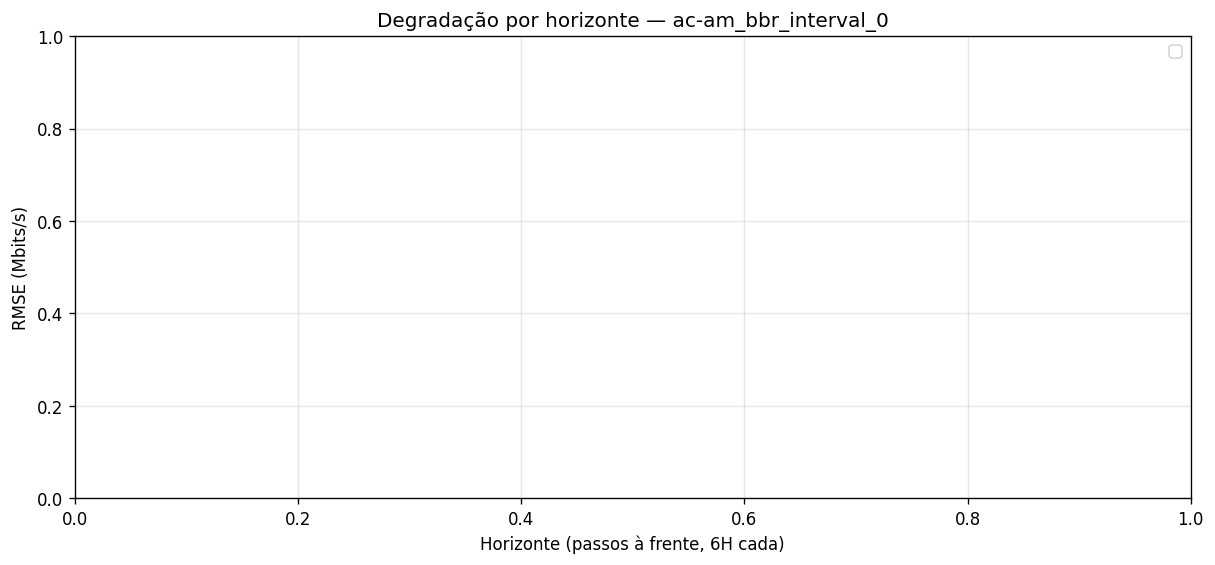

In [37]:
# Plot (RMSE vs Horizonte)
plt.figure(figsize=(12, 5), dpi=120)
x = np.arange(1, H + 1)

for name, curve in rmse_curves.items():
    plt.plot(x, curve, marker=".", label=name)

plt.xlabel("Horizonte (passos à frente, 6H cada)")
plt.ylabel("RMSE (Mbits/s)")
plt.title(f"Degradação por horizonte — {key}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [38]:
def run_horizon_degradation_all(
    H: int,
    stress_rate: float = 0.0,
    sarima_stride: int = 2,
):
    rows = []

    for protocol in ["bbr", "cubic"]:
        data_dir = TREATED_DIR / protocol
        if not data_dir.exists():
            continue

        paths = ModelPaths(
            proposal_dir=(RESULTS_DIR / protocol / "models"),
            gru_lstm_dir=(RESULTS2_DIR / protocol / "models"),
        )

        for csv_path in sorted(data_dir.glob("*.csv")):
            key = dataset_key_from_csv(csv_path)
            link = link_from_key(key)

            try:
                series, _ = prepare_series_6h(csv_path, resample_how=RESAMPLE_HOW)
                if np.sum(np.isfinite(series)) < 10:
                    continue
                train_scaled, test_scaled, scaler, mask_test_real = split_scale(series, train_ratio=TRAIN_RATIO)
            except Exception:
                continue

            model_files = find_model_files(paths, key)

            curves = {}

            if model_files["PROPOSAL"]:
                try:
                    m = keras.models.load_model(model_files["PROPOSAL"], compile=False)
                    curves["PROPOSAL"] = rollout_recursive_proposal(
                        m, train_scaled, test_scaled, scaler, mask_test_real,
                        H=H, look_back=3, stress_rate=stress_rate, seed=SEED
                    )
                except Exception:
                    pass

            if model_files["GRU"]:
                try:
                    m = keras.models.load_model(model_files["GRU"], compile=False)
                    curves["GRU"] = rollout_recursive_lookback1(
                        m, train_scaled, test_scaled, scaler, mask_test_real,
                        H=H, stress_rate=stress_rate, seed=SEED
                    )
                except Exception:
                    pass

            if model_files["LSTM"]:
                try:
                    m = keras.models.load_model(model_files["LSTM"], compile=False)
                    curves["LSTM"] = rollout_recursive_lookback1(
                        m, train_scaled, test_scaled, scaler, mask_test_real,
                        H=H, stress_rate=stress_rate, seed=SEED
                    )
                except Exception:
                    pass

            # SARIMA (sempre roda; pode desativar se quiser)
            try:
                curves["SARIMA"] = rollout_sarima_horizon(
                    train_scaled, test_scaled, scaler, mask_test_real,
                    H=H, stress_rate=stress_rate, seed=SEED, stride=sarima_stride
                )
            except Exception:
                pass

            for model_name, curve in curves.items():
                for h in range(H):
                    rows.append({
                        "link": link,
                        "protocol": protocol,
                        "model": model_name,
                        "stress_rate": float(stress_rate),
                        "horizon": int(h + 1),
                        "rmse": float(curve[h]),
                    })

    return pd.DataFrame(rows)


df_deg = run_horizon_degradation_all(H=H, stress_rate=0.0, sarima_stride=2)
df_deg.head()


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead

,link,protocol,model,stress_rate,horizon,rmse
0,ac-ap,bbr,PROPOSAL,0.0,1,115.311993
1,ac-ap,bbr,PROPOSAL,0.0,2,115.273092
2,ac-ap,bbr,PROPOSAL,0.0,3,114.780405
3,ac-ap,bbr,PROPOSAL,0.0,4,114.499195
4,ac-ap,bbr,PROPOSAL,0.0,5,114.495677


In [39]:
out_path = OUT_DIR / "degradation_horizon_mean.csv"
df_deg.to_csv(out_path, index=False, encoding="utf-8")
out_path


WindowsPath('metrics/degradation_horizon_mean.csv')

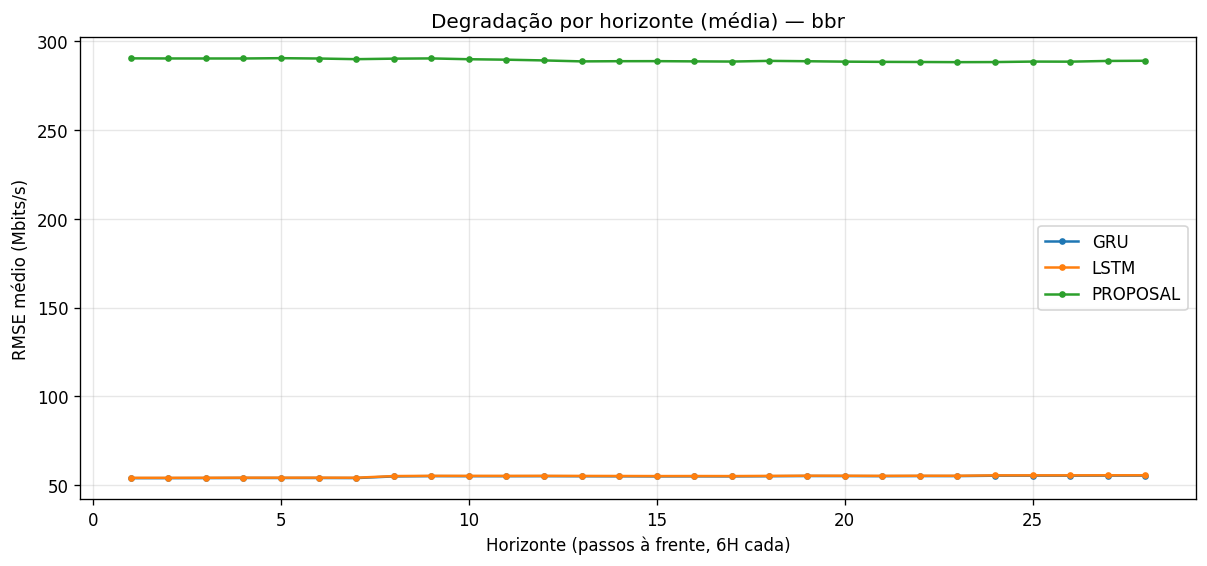

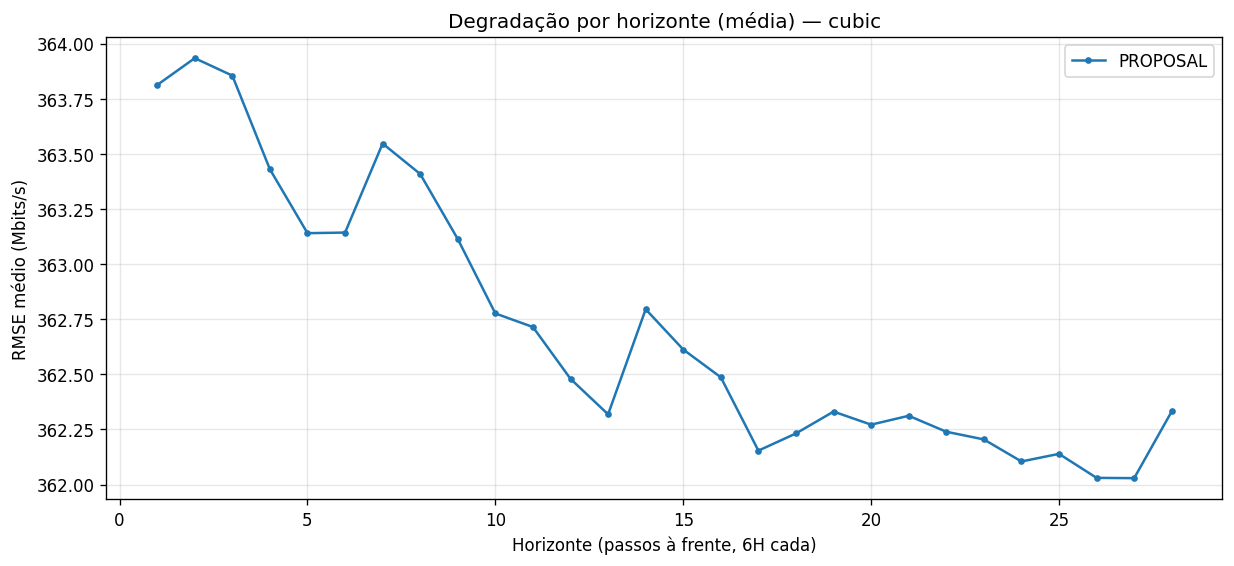

In [40]:
def plot_mean_curve(df_deg: pd.DataFrame, protocol: str):
    g = df_deg[df_deg["protocol"] == protocol].copy()
    if len(g) == 0:
        print("Sem dados para", protocol)
        return

    mean_curve = g.groupby(["model", "horizon"])["rmse"].mean().reset_index()

    plt.figure(figsize=(12, 5), dpi=120)
    for model_name in sorted(mean_curve["model"].unique()):
        s = mean_curve[mean_curve["model"] == model_name].sort_values("horizon")
        plt.plot(s["horizon"], s["rmse"], marker=".", label=model_name)

    plt.xlabel("Horizonte (passos à frente, 6H cada)")
    plt.ylabel("RMSE médio (Mbits/s)")
    plt.title(f"Degradação por horizonte (média) — {protocol}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_mean_curve(df_deg, "bbr")
plot_mean_curve(df_deg, "cubic")


In [41]:
dfs = []
for r in STRESS_RATES:
    print("Rodando stress_rate =", r)
    dfs.append(run_horizon_degradation_all(H=H, stress_rate=r, sarima_stride=4))  # stride=4 pra acelerar no stress

df_stress = pd.concat(dfs, ignore_index=True)
df_stress.head()


Rodando stress_rate = 0.0


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead

Rodando stress_rate = 0.1


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead

Rodando stress_rate = 0.3


...

Rodando stress_rate = 0.5


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead

Rodando stress_rate = 0.7


C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  out = g[["Vazao"]].resample("6H").mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_35940\3361651516.py:62: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead

,link,protocol,model,stress_rate,horizon,rmse
0,ac-ap,bbr,PROPOSAL,0.0,1,115.311993
1,ac-ap,bbr,PROPOSAL,0.0,2,115.273092
2,ac-ap,bbr,PROPOSAL,0.0,3,114.780405
3,ac-ap,bbr,PROPOSAL,0.0,4,114.499195
4,ac-ap,bbr,PROPOSAL,0.0,5,114.495677


In [42]:
out_path = OUT_DIR / "degradation_horizon_stress.csv"
df_stress.to_csv(out_path, index=False, encoding="utf-8")
out_path


WindowsPath('metrics/degradation_horizon_stress.csv')

In [43]:
def plot_stress_curves(df_stress: pd.DataFrame, protocol: str, model: str):
    g = df_stress[(df_stress["protocol"] == protocol) & (df_stress["model"] == model)].copy()
    if len(g) == 0:
        print("Sem dados.")
        return

    mean_curve = g.groupby(["stress_rate", "horizon"])["rmse"].mean().reset_index()

    plt.figure(figsize=(12, 5), dpi=120)
    for r in sorted(mean_curve["stress_rate"].unique()):
        s = mean_curve[mean_curve["stress_rate"] == r].sort_values("horizon")
        plt.plot(s["horizon"], s["rmse"], marker=".", label=f"stress={r}")

    plt.xlabel("Horizonte (passos à frente, 6H cada)")
    plt.ylabel("RMSE médio (Mbits/s)")
    plt.title(f"Stress Test — {protocol} — {model}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()0

plot_stress_curves(df_stress, "bbr", "PROPOSAL")
plot_stress_curves(df_stress, "bbr", "GRU")
plot_stress_curves(df_stress, "bbr", "SARIMA")


SyntaxError: invalid syntax (2753960875.py, line 19)

In [ ]:
# save as: run_degradation_sarima_selected.py
from __future__ import annotations

import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Optional, Tuple, List

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")

# =========================
# Config
# =========================
TRAIN_RATIO = 0.8
RESAMPLE_HOW = "mean"         # "mean" | "sum" | "median" | "max" | "min"
SARIMA_STRIDE = 2             # avalia origens a cada 2 passos (pra acelerar)
H_DEFAULT = 28                # horizonte
STRESS_RATE = 0.0             # aqui só vai pro CSV (como no seu arquivo)

SELECTED = {
    ("ac-pa", "bbr"), ("ac-to", "bbr"), ("ce-pi", "bbr"),
    ("es-ce", "bbr"), ("es-pr", "bbr"), ("go-sp", "bbr"),
    ("ma-es", "bbr"), ("ma-pa", "bbr"), ("ms-to", "bbr"),
    ("mt-ma", "bbr"), ("rs-ac", "bbr"), ("rs-to", "bbr"),
    ("sc-to", "bbr"),
}

# =========================
# Helpers de dados (iguais ao seu pipeline)
# =========================
def bits_para_megabits(series: pd.Series) -> pd.Series:
    s = series.astype("float64") / 1_000_000.0
    s = s.replace(-1, np.nan)
    return s

def linear_interpolation(series: pd.Series) -> pd.Series:
    s = series.copy()
    s_interp = s.interpolate(method="linear", limit_direction="both")
    return s.fillna(s_interp)

def resample_6h(df: pd.DataFrame, how: str = "mean") -> pd.DataFrame:
    g = df.copy()
    g["Data"] = pd.to_datetime(g["Data"], errors="coerce")
    g = g.dropna(subset=["Data"]).sort_values("Data")

    g["Vazao"] = bits_para_megabits(g["Vazao"])
    g = g.set_index("Data")

    if how == "mean":
        agg = g[["Vazao"]].resample("6H").mean()
    elif how == "sum":
        agg = g[["Vazao"]].resample("6H").sum()
    elif how == "median":
        agg = g[["Vazao"]].resample("6H").median()
    elif how == "max":
        agg = g[["Vazao"]].resample("6H").max()
    elif how == "min":
        agg = g[["Vazao"]].resample("6H").min()
    else:
        raise ValueError(f"how inválido: {how}")

    return agg.reset_index()

def split_train_test(values_2d: np.ndarray, train_ratio: float = 0.8) -> Tuple[np.ndarray, np.ndarray]:
    n = len(values_2d)
    n_train = int(n * train_ratio)
    train = values_2d[:n_train]
    test = values_2d[n_train:]
    return train, test

def dataset_key_from_csv(csv_path: Path) -> str:
    return csv_path.stem

def link_from_key(key: str) -> str:
    # ex: "ac-pa_bbr_interval_0" -> "ac-pa"
    return key.split("_")[0].lower()

# =========================
# SARIMA: seleção simples via AIC (igual seu estilo)
# =========================
def select_best_sarima_cfg(y_train: np.ndarray, s: int = 12):
    """
    Procura em grade pequena (0/1) como no seu script SARIMA.
    Retorna (order, seasonal_order).
    """
    p_values = d_values = q_values = [0, 1]
    P_values = D_values = Q_values = [0, 1]

    best_aic = float("inf")
    best_cfg = None

    y = np.asarray(y_train, dtype="float64").ravel()

    for p in p_values:
        for d in d_values:
            for q in q_values:
                for P in P_values:
                    for D in D_values:
                        for Q in Q_values:
                            order = (p, d, q)
                            seasonal_order = (P, D, Q, s)
                            try:
                                m = sm.tsa.SARIMAX(
                                    y,
                                    order=order,
                                    seasonal_order=seasonal_order,
                                    enforce_stationarity=False,
                                    enforce_invertibility=False,
                                )
                                fit = m.fit(disp=False)
                                if fit.aic < best_aic:
                                    best_aic = fit.aic
                                    best_cfg = (order, seasonal_order)
                            except Exception:
                                continue

    if best_cfg is None:
        # fallback bem simples
        best_cfg = ((0, 1, 1), (0, 1, 1, s))

    return best_cfg[0], best_cfg[1]

# =========================
# Degradação por horizonte (rolling origin, recursivo)
# =========================
def sarima_degradation_curve(
    train_scaled: np.ndarray,
    test_scaled: np.ndarray,
    scaler: MinMaxScaler,
    mask_test_real: np.ndarray,
    H: int,
    stride: int = 2,
    seasonal_s: int = 12,
) -> np.ndarray:
    """
    Calcula RMSE por horizonte h=1..H para SARIMA de forma "recursiva",
    avaliando vários pontos de origem no conjunto de teste (a cada 'stride').

    - Fit SARIMA no treino (scaled, 1D)
    - Para cada origem t no teste:
        - gera forecast de H passos
        - compara forecast[h] com valor real em t+h (se existir e for real)
    Retorna: curve_rmse[H]
    """
    y_train = train_scaled.astype("float64").ravel()
    y_test = test_scaled.astype("float64").ravel()
    mask = mask_test_real.astype(bool)

    # escolhe configuração (grade pequena como no seu script)
    order, seasonal_order = select_best_sarima_cfg(y_train, s=seasonal_s)

    # fit no treino
    base_model = sm.tsa.SARIMAX(
        y_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    base_fit = base_model.fit(disp=False)

    # guardamos erros por horizonte
    errs_by_h: List[List[float]] = [[] for _ in range(H)]

    # rolling origin (somente onde dá pra olhar H passos à frente)
    max_origin = len(y_test) - 1
    for t in range(0, max_origin, stride):
        # para cada origem, precisamos do "estado" do modelo atualizado até t
        # estratégia: usar append incremental sem refit (rápido)
        # começamos do fit no treino e vamos "appendando" dados do teste até a origem t
        fit_t = base_fit
        if t > 0:
            # alimenta t pontos do teste no modelo (usando real quando disponível; senão usa o próprio valor do test_scaled)
            # OBS: como você não está "stressando" missing aqui, usar o test_scaled está ok;
            # se quiser, pode substituir missing por forecast 1-step, mas isso aumenta custo.
            endog_to_append = []
            for k in range(t):
                endog_to_append.append(y_test[k])
            try:
                fit_t = fit_t.append(np.array(endog_to_append, dtype="float64"), refit=False)
            except Exception:
                # se append falhar, pula essa origem
                continue

        # forecast H passos
        try:
            fc = fit_t.get_forecast(steps=H).predicted_mean
        except Exception:
            continue

        # avaliar cada horizonte h
        for h in range(1, H + 1):
            idx = t + (h - 1)
            if idx >= len(y_test):
                break
            # só avalia onde o target é "real" (mask True)
            if not mask[idx]:
                continue

            pred_scaled = float(fc[h - 1])
            true_scaled = float(y_test[idx])

            # volta para escala original (Mbits/s)
            pred = float(scaler.inverse_transform([[pred_scaled]])[0, 0])
            true = float(scaler.inverse_transform([[true_scaled]])[0, 0])

            errs_by_h[h - 1].append((pred - true) ** 2)

    # RMSE por horizonte
    curve = np.full(H, np.nan, dtype="float64")
    for h in range(H):
        if len(errs_by_h[h]) > 0:
            curve[h] = float(np.sqrt(np.mean(errs_by_h[h])))

    return curve

# =========================
# Runner (APENAS SARIMA + links selecionados)
# =========================
def run_sarima_only_selected(
    base_dir: Path,
    out_csv: Path,
    H: int = H_DEFAULT,
    resample_how: str = RESAMPLE_HOW,
    sarima_stride: int = SARIMA_STRIDE,
    stress_rate: float = STRESS_RATE,
):
    treated_dir = base_dir / "treated" / "treated"

    rows = []

    # Você pediu: apenas os pares selecionados (todos são bbr)
    protocol = "bbr"
    data_dir = treated_dir / protocol
    if not data_dir.exists():
        raise FileNotFoundError(f"Pasta não encontrada: {data_dir}")

    csv_files = sorted(data_dir.glob("*.csv"))
    print(f"[INFO] {protocol}: {len(csv_files)} CSVs encontrados")

    for csv_path in csv_files:
        key = dataset_key_from_csv(csv_path)
        link = link_from_key(key)

        if (link, protocol) not in SELECTED:
            continue

        # carrega e trata 6h
        try:
            df = pd.read_csv(csv_path)
        except Exception as e:
            print(f"[ERRO] Lendo {csv_path.name}: {e}")
            continue

        if not {"Data", "Vazao"}.issubset(df.columns):
            print(f"[SKIP] {csv_path.name}: faltando colunas (Data, Vazao).")
            continue

        df6 = resample_6h(df, how=resample_how)
        series = df6["Vazao"].astype("float64").values  # Mbits/s, com NaNs possíveis

        valid_count = np.sum(~pd.isna(series))
        if valid_count < 10:
            print(f"[SKIP] {key}: poucos pontos válidos após 6h (valid={valid_count}).")
            continue

        # pipeline: mask, interp no treino, scaler fit treino
        s2d = series.reshape(-1, 1)

        mask_total = ~pd.isna(s2d.flatten())
        train, test = split_train_test(s2d, train_ratio=TRAIN_RATIO)

        train_mask = mask_total[: len(train)]
        test_mask = mask_total[len(train):]

        train_interp = linear_interpolation(pd.Series(train.flatten())).values.reshape(-1, 1)

        scaler = MinMaxScaler().fit(train_interp)
        train_scaled = scaler.transform(train_interp)
        test_scaled = scaler.transform(test)

        mask_test_real = test_mask.astype(bool)

        # curva de degradação
        try:
            curve = sarima_degradation_curve(
                train_scaled=train_scaled,
                test_scaled=test_scaled,
                scaler=scaler,
                mask_test_real=mask_test_real,
                H=H,
                stride=sarima_stride,
                seasonal_s=12,
            )
        except Exception as e:
            print(f"[ERRO] {key} SARIMA curve: {e}")
            continue

        # salva no formato padrão do seu degradation csv
        for h in range(H):
            if np.isfinite(curve[h]):
                rows.append({
                    "link": link,
                    "protocol": protocol,
                    "model": "SARIMA",
                    "stress_rate": float(stress_rate),
                    "horizon": int(h + 1),
                    "rmse": float(curve[h]),
                })

        print(f"[OK] {key}: SARIMA curve gerada (H={H})")

    out_csv.parent.mkdir(parents=True, exist_ok=True)
    out_df = pd.DataFrame(rows).sort_values(["link", "protocol", "model", "stress_rate", "horizon"])
    out_df.to_csv(out_csv, index=False, encoding="utf-8")
    print(f"\n[DONE] Salvou: {out_csv} (rows={len(out_df)})")


if __name__ == "__main__":
    # ajuste base_dir conforme sua estrutura
    BASE_DIR = Path(".")  # raiz do projeto
    OUT_CSV = Path("results_sbrc_26/metrics/degradation_horizon_sarima_selected_links.csv")

    run_sarima_only_selected(
        base_dir=BASE_DIR,
        out_csv=OUT_CSV,
        H=28,
        resample_how="mean",
        sarima_stride=2,
        stress_rate=0.0,
    )


[INFO] bbr: 399 CSVs encontrados
[OK] ac-pa_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] ac-to_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] ce-pi_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] es-ce_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] es-pr_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] go-sp_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] ma-es_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] ma-pa_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] ms-to_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] mt-ma_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] rs-ac_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] rs-to_bbr_interval_0: SARIMA curve gerada (H=28)
[OK] sc-to_bbr_interval_0: SARIMA curve gerada (H=28)

[DONE] Salvou: results_sbrc_26\metrics\degradation_horizon_sarima_selected_links.csv (rows=364)


: 